In [1]:
import pandas as pd
import numpy as np

# Load AmeriFlux dataset (skip metadata rows)
df_amf = pd.read_csv(
    "AMF_US-ARM_BASE_HH_15-5.csv",
    skiprows=2  # very important for AmeriFlux files
)

# Check columns
print(df_amf.columns[:10])
print(df_amf.head())

ParserError: Error tokenizing data. C error: Calling read(nbytes) on source failed. Try engine='python'.

In [ ]:
# Recreate SWC column list
swc_cols = [col for col in df_amf.columns if 'SWC' in col]

# Print all SWC columns
for col in swc_cols:
    print(col)

# Also print total count
print("\nTotal SWC columns:", len(swc_cols))

SWC_1_2_1
SWC_1_2_2
SWC_1_1_1
SWC_1_1_2
SWC_1_2_3
SWC_1_2_4
SWC_1_1_3
SWC_1_1_4
SWC_2_1_1
SWC_2_2_1
SWC_2_3_1
SWC_2_4_1
SWC_2_5_1
SWC_2_6_1
SWC_3_1_1
SWC_3_1_2
SWC_3_2_1
SWC_3_2_2
SWC_3_3_1
SWC_3_3_2

Total SWC columns: 20


In [ ]:
import pandas as pd
import numpy as np

# Step 1: Convert timestamp to datetime
df_amf['TIMESTAMP_START'] = pd.to_datetime(df_amf['TIMESTAMP_START'], format='%Y%m%d%H%M')

# Step 2: Set datetime as index (VERY IMPORTANT)
df_amf = df_amf.set_index('TIMESTAMP_START')

# Step 3: Select shallow sensors (5–10 cm)
swc_combined_cols = [col for col in df_amf.columns if col.startswith('SWC_1')]

print("Selected shallow sensors:")
print(swc_combined_cols)

# Step 4: Replace invalid values
df_amf[swc_combined_cols] = df_amf[swc_combined_cols].replace(-9999, np.nan)

# Step 5: Average sensors
df_amf['SWC_combined_avg'] = df_amf[swc_combined_cols].mean(axis=1)

# Step 6: Convert % to fraction
df_amf['SWC_combined_avg'] = df_amf['SWC_combined_avg'] / 100

# 🔥 IMPORTANT CHECK
print("\nIndex type:", type(df_amf.index))

# Step 7: Convert to hourly
df_amf_hourly = df_amf['SWC_combined_avg'].resample('h').mean()

# Step 8: Drop NaN
df_amf_hourly = df_amf_hourly.dropna()

# Step 9: Show results
print("\nHourly Data:")
print(df_amf_hourly.head())

print("\nSummary:")
print(df_amf_hourly.describe())

Selected shallow sensors:
['SWC_1_2_1', 'SWC_1_2_2', 'SWC_1_1_1', 'SWC_1_1_2', 'SWC_1_2_3', 'SWC_1_2_4', 'SWC_1_1_3', 'SWC_1_1_4']

Index type: <class 'pandas.DatetimeIndex'>

Hourly Data:
TIMESTAMP_START
2003-01-01 18:00:00    0.280129
2003-01-01 19:00:00    0.279750
2003-01-01 20:00:00    0.279557
2003-01-01 21:00:00    0.279250
2003-01-01 22:00:00    0.279014
Name: SWC_combined_avg, dtype: float64

Summary:
count    78816.000000
mean         0.258792
std          0.084159
min          0.000000
25%          0.200211
50%          0.250180
75%          0.323625
max          0.499900
Name: SWC_combined_avg, dtype: float64


C:\Users\prath\AppData\Local\Temp\ipykernel_4204\1350842250.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_amf['SWC_combined_avg'] = df_amf[swc_combined_cols].mean(axis=1)


In [ ]:
# Load ERA5 data
df_era5 = pd.read_csv("reanalysis-era5-land-timeseries-sfc-soil-watery5wmeq3m.csv")

# Print all column names clearly
for col in df_era5.columns:
    print(col)

print("\nFirst few rows:")
print(df_era5.head())

valid_time
swvl1
latitude
longitude

First few rows:
            valid_time     swvl1  latitude  longitude
0  2003-01-01 00:00:00  0.328949      36.5      -97.5
1  2003-01-01 01:00:00  0.328629      36.5      -97.5
2  2003-01-01 02:00:00  0.328323      36.5      -97.5
3  2003-01-01 03:00:00  0.328064      36.5      -97.5
4  2003-01-01 04:00:00  0.327805      36.5      -97.5


In [ ]:
import pandas as pd

# Convert valid_time to datetime
df_era5['valid_time'] = pd.to_datetime(df_era5['valid_time'])

# Set time as index
df_era5 = df_era5.set_index('valid_time')

# Keep only soil moisture column
df_era5 = df_era5[['swvl1']]

# Drop missing values (if any)
df_era5 = df_era5.dropna()

# Show results
print("\nERA5 Prepared Data:")
print(df_era5.head())

print("\nSummary:")
print(df_era5.describe())


ERA5 Prepared Data:
                        swvl1
valid_time                   
2003-01-01 00:00:00  0.328949
2003-01-01 01:00:00  0.328629
2003-01-01 02:00:00  0.328323
2003-01-01 03:00:00  0.328064
2003-01-01 04:00:00  0.327805

Summary:
               swvl1
count  201624.000000
mean        0.265774
std         0.075181
min         0.136597
25%         0.202744
50%         0.268143
75%         0.324463
max         0.438995


In [ ]:
import pandas as pd

# Combine datasets based on time index
df_compare = pd.concat([
    df_amf_hourly.rename("AmeriFlux"),
    df_era5['swvl1'].rename("ERA5")
], axis=1)

# Drop rows with missing values
df_compare = df_compare.dropna()

# Show combined data
print("\nCombined Dataset:")
print(df_compare.head())

# Compute correlation
correlation = df_compare.corr()

print("\nCorrelation Matrix:")
print(correlation)


Combined Dataset:
                     AmeriFlux      ERA5
2003-01-01 18:00:00   0.280129  0.323135
2003-01-01 19:00:00   0.279750  0.322495
2003-01-01 20:00:00   0.279557  0.321869
2003-01-01 21:00:00   0.279250  0.321381
2003-01-01 22:00:00   0.279014  0.321121

Correlation Matrix:
           AmeriFlux      ERA5
AmeriFlux   1.000000  0.563736
ERA5        0.563736  1.000000


C:\Users\prath\AppData\Local\Temp\ipykernel_4204\3543945903.py:4: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df_compare = pd.concat([


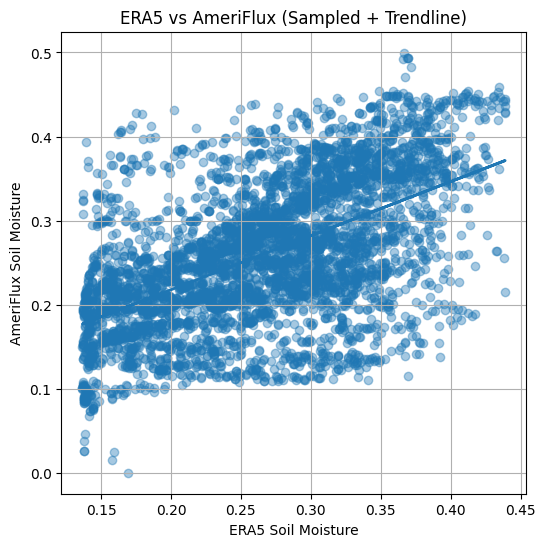

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Take random sample (to reduce crowding)
df_sample = df_compare.sample(n=5000, random_state=42)

plt.figure(figsize=(6,6))

# Scatter plot
plt.scatter(df_sample['ERA5'], df_sample['AmeriFlux'], alpha=0.4)

# Add trend line (linear fit)
z = np.polyfit(df_sample['ERA5'], df_sample['AmeriFlux'], 1)
p = np.poly1d(z)

plt.plot(df_sample['ERA5'], p(df_sample['ERA5']), linewidth=2)

plt.xlabel("ERA5 Soil Moisture")
plt.ylabel("AmeriFlux Soil Moisture")
plt.title("ERA5 vs AmeriFlux (Sampled + Trendline)")

plt.grid()
plt.show()

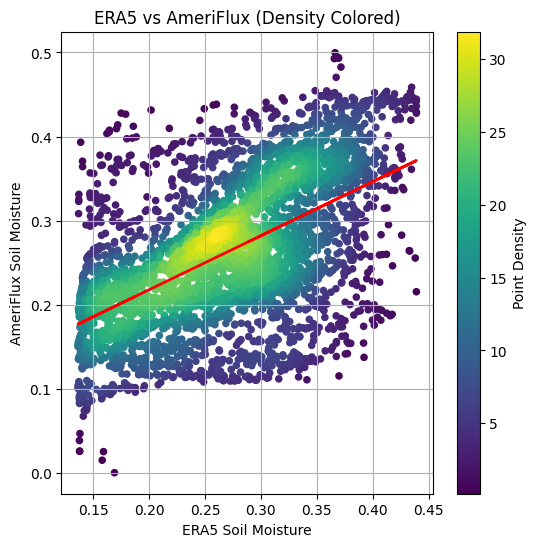

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

# Take sample (important for speed)
df_sample = df_compare.sample(n=5000, random_state=42)

x = df_sample['ERA5']
y = df_sample['AmeriFlux']

# Calculate density
xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)

plt.figure(figsize=(6,6))

# Scatter with color based on density
scatter = plt.scatter(x, y, c=z, cmap='viridis', s=20)

# Add colorbar
plt.colorbar(scatter, label='Point Density')

# Add trend line
m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, color='red', linewidth=2)

plt.xlabel("ERA5 Soil Moisture")
plt.ylabel("AmeriFlux Soil Moisture")
plt.title("ERA5 vs AmeriFlux (Density Colored)")

plt.grid()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# -----------------------------
# Step 1: Prepare data
# -----------------------------
X = df_compare[['ERA5']]
y = df_compare['AmeriFlux']

# -----------------------------
# Step 2: Train-test split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# -----------------------------
# Step 3: Define model
# -----------------------------
model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42
)

# -----------------------------
# Step 4: Train model
# -----------------------------
model.fit(X_train, y_train)

# -----------------------------
# Step 5: Predictions
# -----------------------------
y_train_pred = model.predict(X_train)   # Calibration
y_test_pred = model.predict(X_test)     # Validation

# -----------------------------
# Step 6: Evaluation function
# -----------------------------
def evaluate(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"\n{name} Results:")
    print("RMSE:", rmse)
    print("R2 Score:", r2)

# -----------------------------
# Step 7: Print results
# -----------------------------
evaluate(y_train, y_train_pred, "Calibration (Train)")
evaluate(y_test, y_test_pred, "Validation (Test)")


Calibration (Train) Results:
RMSE: 0.06886861845470625
R2 Score: 0.33123723680684913

Validation (Test) Results:
RMSE: 0.06900787848772598
R2 Score: 0.3255039943111473


In [ ]:
# Sort data by time (VERY IMPORTANT)
df_compare = df_compare.sort_index()

# Define split index (70%)
split_index = int(len(df_compare) * 0.7)

# Split data
train = df_compare.iloc[:split_index]
test = df_compare.iloc[split_index:]

# Separate features and target
X_train = train[['ERA5']]
y_train = train['AmeriFlux']

X_test = test[['ERA5']]
y_test = test['AmeriFlux']

print("Train period:", train.index.min(), "to", train.index.max())
print("Test period:", test.index.min(), "to", test.index.max())

Train period: 2003-01-01 18:00:00 to 2011-03-07 08:00:00
Test period: 2011-03-07 09:00:00 to 2015-02-27 12:00:00


In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Model
model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42
)

# Train
model.fit(X_train, y_train)

# Predict
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Evaluation
def evaluate(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"\n{name}:")
    print("RMSE:", rmse)
    print("R2:", r2)

evaluate(y_train, y_train_pred, "Calibration (Train)")
evaluate(y_test, y_test_pred, "Validation (Test)")


Calibration (Train):
RMSE: 0.06882785986639962
R2: 0.3432169234253414

Validation (Test):
RMSE: 0.07225120108308561
R2: 0.0004157438312548667


In [ ]:
# Check start and end time of AmeriFlux hourly data
print("Start time:", df_amf_hourly.index.min())
print("End time:", df_amf_hourly.index.max())

# Also check total number of records
print("Total records:", len(df_amf_hourly))

Start time: 2003-01-01 18:00:00
End time: 2015-02-27 12:00:00
Total records: 78816


In [ ]:
# Select shallow sensors
swc_combined_cols = [col for col in df_amf.columns if col.startswith('SWC_1')]

# Replace invalid values
df_amf[swc_combined_cols] = df_amf[swc_combined_cols].replace(-9999, np.nan)

# Average sensors (ignore NaN properly)
df_amf['SWC_combined_avg'] = df_amf[swc_combined_cols].mean(axis=1)

# Convert to fraction
df_amf['SWC_combined_avg'] = df_amf['SWC_combined_avg'] / 100

# Convert to hourly
df_amf_hourly = df_amf['SWC_combined_avg'].resample('h').mean()

# ❗ DO NOT DROP ALL NaNs blindly
# Instead, keep data and drop only where SWC is missing
df_amf_hourly = df_amf_hourly[df_amf_hourly.notna()]

# Check range again
print("Start:", df_amf_hourly.index.min())
print("End:", df_amf_hourly.index.max())

Start: 2003-01-01 18:00:00
End: 2015-02-27 12:00:00


In [ ]:
import pandas as pd
import numpy as np

# Select ALL SWC columns (important change)
swc_cols = [col for col in df_amf.columns if 'SWC' in col]

print("Total SWC sensors:", len(swc_cols))

# Replace invalid values
df_amf[swc_cols] = df_amf[swc_cols].replace(-9999, np.nan)

# Count how many sensors are available at each time
df_amf['valid_sensor_count'] = df_amf[swc_cols].notna().sum(axis=1)

# Keep rows where at least 1 sensor exists
df_amf = df_amf[df_amf['valid_sensor_count'] > 0]

# Average across available sensors (this is the key fix)
df_amf['SWC_avg'] = df_amf[swc_cols].mean(axis=1)

# Convert to fraction
df_amf['SWC_avg'] = df_amf['SWC_avg'] / 100

# Convert to hourly
df_amf_hourly = df_amf['SWC_avg'].resample('h').mean()

# Drop only rows where final value is NaN
df_amf_hourly = df_amf_hourly.dropna()

# Check range again
print("Start:", df_amf_hourly.index.min())
print("End:", df_amf_hourly.index.max())
print("Total samples:", len(df_amf_hourly))

Total SWC sensors: 21


C:\Users\prath\AppData\Local\Temp\ipykernel_4204\586560765.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_amf['valid_sensor_count'] = df_amf[swc_cols].notna().sum(axis=1)


Start: 2003-01-01 18:00:00
End: 2026-01-01 17:00:00
Total samples: 168226


C:\Users\prath\AppData\Local\Temp\ipykernel_4204\586560765.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_amf['SWC_avg'] = df_amf[swc_cols].mean(axis=1)


In [ ]:
# Check time difference between consecutive timestamps
print(df_amf_hourly.index.to_series().diff().value_counts().head())


TIMESTAMP_START
0 days 01:00:00    168030
1 days 01:00:00        61
0 days 02:00:00        20
0 days 03:00:00        13
0 days 04:00:00         9
Name: count, dtype: int64


In [ ]:
print(df_era5.index.to_series().diff().value_counts().head())

valid_time
0 days 01:00:00    201623
Name: count, dtype: int64


In [ ]:
df_compare = pd.concat([
    df_amf_hourly.rename("AmeriFlux"),
    df_era5['swvl1'].rename("ERA5")
], axis=1, sort=False)

# Keep only rows where both exist
df_compare = df_compare.dropna()

print("Start:", df_compare.index.min())
print("End:", df_compare.index.max())
print("Total samples:", len(df_compare))

Start: 2003-01-01 18:00:00
End: 2025-12-31 23:00:00
Total samples: 168208


In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Sort data (important for time-based split)
df_compare = df_compare.sort_index()

# Split index (70%)
split_index = int(len(df_compare) * 0.7)

# Split data
train = df_compare.iloc[:split_index]
test = df_compare.iloc[split_index:]

# Features and target
X_train = train[['ERA5']]
y_train = train['AmeriFlux']

X_test = test[['ERA5']]
y_test = test['AmeriFlux']

# Model
model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42
)

# Train
model.fit(X_train, y_train)

# Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Evaluation function
def evaluate(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"\n{name}")
    print("RMSE:", rmse)
    print("R2:", r2)

# Results
evaluate(y_train, y_train_pred, "Calibration (Train)")
evaluate(y_test, y_test_pred, "Validation (Test)")


Calibration (Train)
RMSE: 0.08489848736467612
R2: 0.1961392588015306

Validation (Test)
RMSE: 0.12132310131934824
R2: -4.005450128792754


In [ ]:
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# -----------------------------
# Step 1: Prepare data
# -----------------------------
X = df_compare[['ERA5']]
y = df_compare['AmeriFlux']

# -----------------------------
# Step 2: RANDOM split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# -----------------------------
# Step 3: Model
# -----------------------------
model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42
)

# -----------------------------
# Step 4: Train
# -----------------------------
model.fit(X_train, y_train)

# -----------------------------
# Step 5: Predictions
# -----------------------------
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# -----------------------------
# Step 6: Evaluation
# -----------------------------
def evaluate(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"\n{name}")
    print("RMSE:", rmse)
    print("R2:", r2)

# Calibration (train)
evaluate(y_train, y_train_pred, "Calibration (Train)")

# Validation (test)
evaluate(y_test, y_test_pred, "Validation (Test)")


Calibration (Train)
RMSE: 0.09095667957493372
R2: 0.15004934944961335

Validation (Test)
RMSE: 0.0908982359580985
R2: 0.14990092347838424


In [ ]:
# ERA5 baseline (no ML)
rmse_era5 = np.sqrt(mean_squared_error(y_test, X_test['ERA5']))
r2_era5 = r2_score(y_test, X_test['ERA5'])

print("\nERA5 Baseline (Test)")
print("RMSE:", rmse_era5)
print("R2:", r2_era5)


ERA5 Baseline (Test)
RMSE: 0.1066305787131176
R2: -0.16982841682522687


In [ ]:
df_aug2015 = df_compare.loc['2015-08-01':'2015-08-31']

# Add ML prediction
df_aug2015['ML_Model'] = model.predict(df_aug2015[['ERA5']])

print(df_aug2015.head())

                     AmeriFlux      ERA5  ML_Model
2015-08-01 00:00:00   0.436803  0.192230  0.260835
2015-08-01 01:00:00   0.436627  0.192108  0.260835
2015-08-01 02:00:00   0.436433  0.192017  0.260835
2015-08-01 03:00:00   0.436253  0.191971  0.260835
2015-08-01 04:00:00   0.436153  0.191940  0.260835


In [ ]:
# Convert hourly to daily (mean aggregation)
df_aug2015_daily = df_aug2015.resample('D').mean()

# Drop days with missing values (if any)
df_aug2015_daily = df_aug2015_daily.dropna()

# Show result
print(df_aug2015_daily.head())
print("\nTotal days:", len(df_aug2015_daily))

            AmeriFlux      ERA5  ML_Model
2015-08-01   0.435057  0.190009  0.264931
2015-08-02   0.431214  0.178831  0.268298
2015-08-03   0.427124  0.169078  0.260493
2015-08-04   0.431139  0.211293  0.281000
2015-08-05   0.434035  0.275410  0.305596

Total days: 31


In [ ]:
smap_folder = "."

In [ ]:
import os
print(os.getcwd())

c:\Users\prath\OneDrive\Desktop\Remote Sensing in Ecohydology\Final_Project


In [ ]:
with h5py.File(file_path, 'r') as f:
    print(list(f.keys()))

NameError: name 'h5py' is not defined

In [ ]:
with h5py.File(file_path, 'r') as f:
    print(list(f['Soil_Moisture_Retrieval_Data_AM'].keys()))

['EASE_column_index', 'EASE_row_index', 'albedo', 'albedo_dca', 'albedo_scah', 'albedo_scav', 'boresight_incidence', 'bulk_density', 'clay_fraction', 'freeze_thaw_fraction', 'grid_surface_status', 'latitude', 'latitude_centroid', 'longitude', 'longitude_centroid', 'radar_water_body_fraction', 'retrieval_qual_flag', 'retrieval_qual_flag_dca', 'retrieval_qual_flag_scah', 'retrieval_qual_flag_scav', 'roughness_coefficient', 'roughness_coefficient_dca', 'roughness_coefficient_scah', 'roughness_coefficient_scav', 'soil_moisture', 'soil_moisture_dca', 'soil_moisture_error', 'soil_moisture_scah', 'soil_moisture_scav', 'static_water_body_fraction', 'surface_flag', 'surface_temperature', 'surface_water_fraction_mb_h', 'surface_water_fraction_mb_v', 'tb_3_corrected', 'tb_4_corrected', 'tb_h_corrected', 'tb_h_uncorrected', 'tb_qual_flag_3', 'tb_qual_flag_4', 'tb_qual_flag_h', 'tb_qual_flag_v', 'tb_time_seconds', 'tb_time_utc', 'tb_v_corrected', 'tb_v_uncorrected', 'vegetation_opacity', 'vegetatio

In [ ]:
for file in sorted(os.listdir(smap_folder)):
    if file.endswith(".h5"):
        file_path = os.path.join(smap_folder, file)

        with h5py.File(file_path, 'r') as f:

            sm = f['Soil_Moisture_Retrieval_Data_AM/soil_moisture'][:]
            lat = f['Soil_Moisture_Retrieval_Data_AM/latitude'][:]
            lon = f['Soil_Moisture_Retrieval_Data_AM/longitude'][:]

            # Target location
            target_lat = 36.5
            target_lon = -97.5

            dist = (lat - target_lat)**2 + (lon - target_lon)**2
            idx = np.unravel_index(np.argmin(dist), dist.shape)

            sm_value = sm[idx]

            # Extract date
            date = file.split('_')[5]
            date = pd.to_datetime(date, format='%Y%m%d')

            smap_data.append([date, sm_value])

In [ ]:
df_smap = pd.DataFrame(smap_data, columns=['Date', 'SMAP']).set_index('Date')

print(df_smap.head())
print("Total days:", len(df_smap))

                SMAP
Date                
2015-08-01  0.135889
2015-08-02  0.138808
2015-08-03  0.126934
2015-08-04  0.088607
2015-08-05  0.071323
Total days: 62


In [ ]:
df_smap = df_smap.resample('D').mean()

print(df_smap.head())
print("Total days:", len(df_smap))

                SMAP
Date                
2015-08-01  0.135889
2015-08-02  0.138808
2015-08-03  0.126934
2015-08-04  0.088607
2015-08-05  0.071323
Total days: 31


In [ ]:
df_final = df_aug2015_daily.join(df_smap, how='inner')

print(df_final.head())
print("Final size:", len(df_final))

            AmeriFlux      ERA5  ML_Model      SMAP
2015-08-01   0.435057  0.190009  0.264931  0.135889
2015-08-02   0.431214  0.178831  0.268298  0.138808
2015-08-03   0.427124  0.169078  0.260493  0.126934
2015-08-04   0.431139  0.211293  0.281000  0.088607
2015-08-05   0.434035  0.275410  0.305596  0.071323
Final size: 31


In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse_era5 = np.sqrt(mean_squared_error(df_final['AmeriFlux'], df_final['ERA5']))
rmse_ml = np.sqrt(mean_squared_error(df_final['AmeriFlux'], df_final['ML_Model']))
rmse_smap = np.sqrt(mean_squared_error(df_final['AmeriFlux'], df_final['SMAP']))

print("\nFINAL RMSE COMPARISON:")
print("ERA5 :", rmse_era5)
print("ML   :", rmse_ml)
print("SMAP :", rmse_smap)


FINAL RMSE COMPARISON:
ERA5 : 0.17822466465619943
ML   : 0.10388228339800501
SMAP : 0.23738726050445233


In [ ]:
print(df_final.corr())

           AmeriFlux      ERA5  ML_Model      SMAP
AmeriFlux   1.000000 -0.364309 -0.396103 -0.406069
ERA5       -0.364309  1.000000  0.949303  0.546311
ML_Model   -0.396103  0.949303  1.000000  0.612933
SMAP       -0.406069  0.546311  0.612933  1.000000


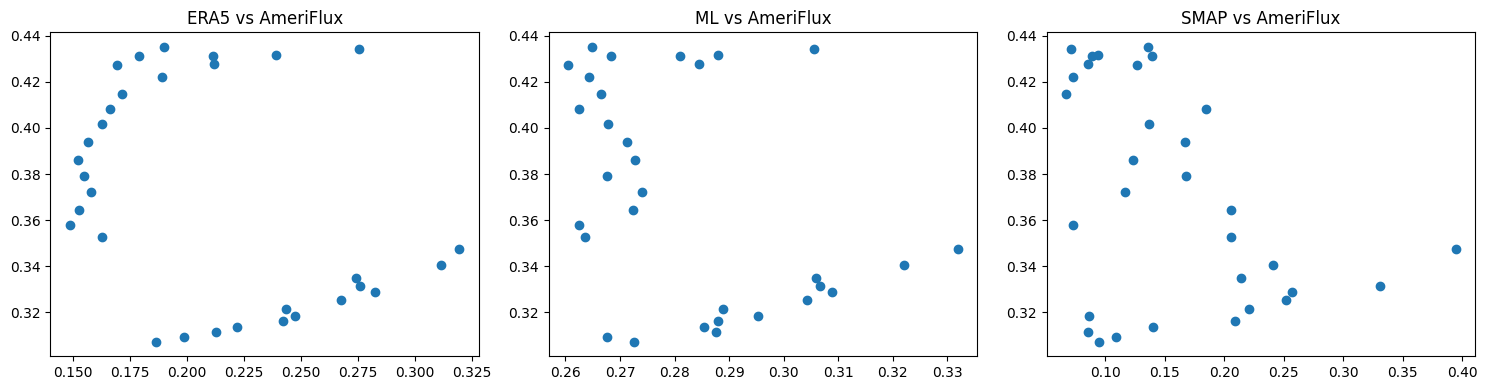

In [ ]:
import matplotlib.pyplot as plt

# AmeriFlux vs others
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.scatter(df_final['ERA5'], df_final['AmeriFlux'])
plt.title("ERA5 vs AmeriFlux")

plt.subplot(1,3,2)
plt.scatter(df_final['ML_Model'], df_final['AmeriFlux'])
plt.title("ML vs AmeriFlux")

plt.subplot(1,3,3)
plt.scatter(df_final['SMAP'], df_final['AmeriFlux'])
plt.title("SMAP vs AmeriFlux")

plt.tight_layout()
plt.show()

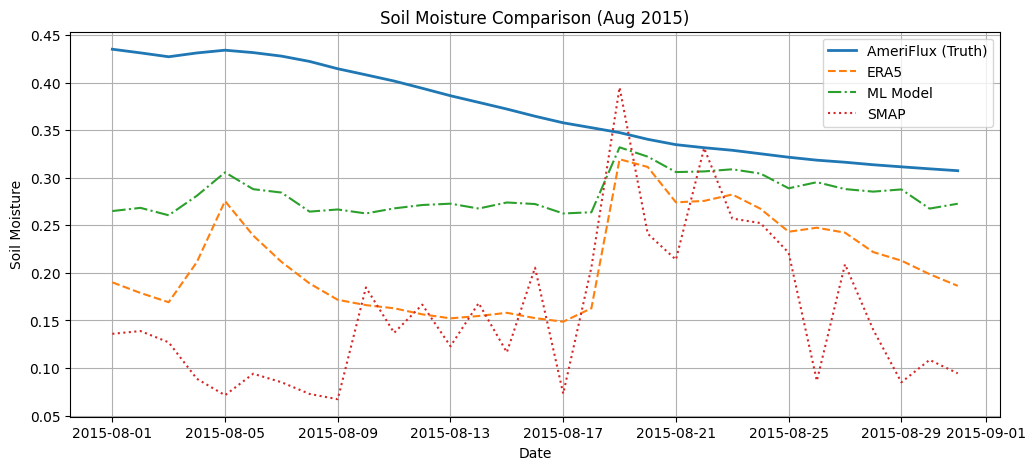

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(df_final.index, df_final['AmeriFlux'], label='AmeriFlux (Truth)', linewidth=2)
plt.plot(df_final.index, df_final['ERA5'], label='ERA5', linestyle='--')
plt.plot(df_final.index, df_final['ML_Model'], label='ML Model', linestyle='-.')
plt.plot(df_final.index, df_final['SMAP'], label='SMAP', linestyle=':')

plt.xlabel("Date")
plt.ylabel("Soil Moisture")
plt.title("Soil Moisture Comparison (Aug 2015)")
plt.legend()
plt.grid()

plt.show()